# LAB 09 — Bias, Variance and Imbalanced Data 
## Student Information 
Name:Sadia Fatima
Student ID:023-24-0213 
Section:G
GitHub:https://github.com/Sadia-Farooque/Machine_Learning.git
Kaggle:https://www.kaggle.com/anamfarooque
Dataset: Stroke Prediction Dataset (Kaggle) 
Dataset Source: https://www.kaggle.com/datasets/fedesoriano/stroke-prediction
dataset

Part 0- setp and the data 

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

df=p.read_csv("healthcare-dataset-stroke-data_1.csv")
print("Shape:", df.shape)
print("\nMissing values:", df.isnull().sum())
print("\nGender counts:", df['gender'].value_counts())
print("\nStroke counts:", df['stroke'].value_counts())
print("\nStroke %:", df['stroke'].value_counts(normalize=True) * 100)

df = df.drop(columns='id')            
df = df[df['gender'] != 'Other']     
df = pd.get_dummies(df, drop_first=True, dtype=int)   

print(df.shape)

Shape: (5110, 12)

Missing values: id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64

Gender counts: gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64

Stroke counts: stroke
0    4861
1     249
Name: count, dtype: int64

Stroke %: stroke
0    95.127202
1     4.872798
Name: proportion, dtype: float64
(5109, 16)


In [ ]:
X = df.drop(columns='stroke')
y = df['stroke']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

medians = X_train.median()
X_train = X_train.fillna(medians)
X_test = X_test.fillna(medians)


scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)

print("Train strokes:", y_train.sum(), "of", len(y_train))
print("Test strokes:", y_test.sum(), "of", len(y_test))

Train strokes: 199 of 4087
Test strokes: 50 of 1022


The data is highly imbalanced. Only 249 of 5,109 patients (4.87%) had a stroke, so there are about 19.5 non-stroke patients for every stroke patient. After the 80/20 split, the training set has 199 strokes out of 4,087 patients (4.87%) and the test set has 50 strokes out of 1,022 patients (4.89%). We used stratify=y to keep the stroke rate almost identical in both sets. Without it, a random split could have given the test set noticeably more or fewer strokes, making the evaluation unfair. Because the test set has only 50 stroke cases, each missed or caught stroke changes recall by 2% (1/50). Our test metrics will therefore be noisy, and small differences between models may just be luck.

part 1 - the accuracy trap 

In [7]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score,
                             confusion_matrix)

def evaluate(model, X_tr, y_tr, X_te, y_te):
    model.fit(X_tr, y_tr)
    pred = model.predict(X_te)                
    prob = model.predict_proba(X_te)[:, 1]    
    return {
        'Accuracy':  accuracy_score(y_te, pred),
        'Precision': precision_score(y_te, pred, zero_division=0),
        'Recall':    recall_score(y_te, pred),
        'F1':        f1_score(y_te, pred, zero_division=0),
        'ROC AUC':   roc_auc_score(y_te, prob),
        'PR AUC':    average_precision_score(y_te, prob)
    }

In [8]:
dummy = DummyClassifier(strategy='most_frequent')
lr = LogisticRegression(max_iter=1000, random_state=42)

results = pd.DataFrame({
    'Always No-Stroke': evaluate(dummy, X_train, y_train, X_test, y_test),
    'Logistic Regression': evaluate(lr, X_train_s, y_train, X_test_s, y_test)
}).T
print(results.round(3))

print("\nLR Confusion Matrix:")
print(confusion_matrix(y_test, lr.predict(X_test_s)))

                     Accuracy  Precision  Recall     F1  ROC AUC  PR AUC
Always No-Stroke        0.951        0.0    0.00  0.000    0.500   0.049
Logistic Regression     0.952        1.0    0.02  0.039    0.839   0.269

LR Confusion Matrix:
[[972   0]
 [ 49   1]]


interpretation:
Both models reach about 95% accuracy, but the Dummy has no skill (ROC AUC 0.500) and Logistic Regression catches only 1 of 50 strokes (recall 0.02, 49 missed), even though its ROC AUC of 0.839 shows it ranks patients well. Accuracy hides the failure, and the 0.5 threshold is too high for this imbalanced data.

(a) Both models reach almost the same accuracy of about 95%. The Dummy classifier gets 95.1% simply by predicting “no stroke” for everyone, without learning anything from the data. Logistic Regression, which was actually trained on the patient features, scores about the same. This shows that accuracy is misleading on imbalanced data: since 95% of patients are healthy, a useless model still looks excellent. In healthcare this is dangerous, because a model that misses every stroke patient could be reported as 95% accurate. So we cannot judge models by accuracy alone. We need metrics that focus on the rare stroke class: precision, recall and F1 tell us how well the model actually finds stroke patients, and ROC AUC and PR AUC tell us how well it ranks high-risk patients above low-risk ones. These metrics show the real difference between the two models: the dummy has 0 recall and an AUC of 0.5 (no skill), while Logistic Regression has a much higher AUC.

(b)The confusion matrix shows that Logistic Regression catches almost none of the ~50 stroke patients, so its recall is close to 0. A false negative means a patient who will have a stroke is told they are fine and sent home without treatment. That is the most dangerous error for a hospital. Instead of accuracy, we should trust recall (how many strokes we catch), precision, F1, and especially ROC AUC and PR AUC. These focus on the stroke class and on how well the model ranks risky patients. 

Part -2 Underfitting, Overfitting, Bias and Variance

   max_depth  Train AUC  CV AUC
0          1      0.717   0.732
1          2      0.821   0.817
2          3      0.838   0.816
3          4      0.858   0.818
4          5      0.876   0.792
5          6      0.903   0.759
6          7      0.928   0.738
7          8      0.949   0.714
8          9      0.968   0.681
9         10      0.981   0.641
10        11      0.991   0.611
11        12      0.996   0.613
12        13      0.998   0.596
13        14      1.000   0.589
14        15      1.000   0.578
15      None      1.000   0.564


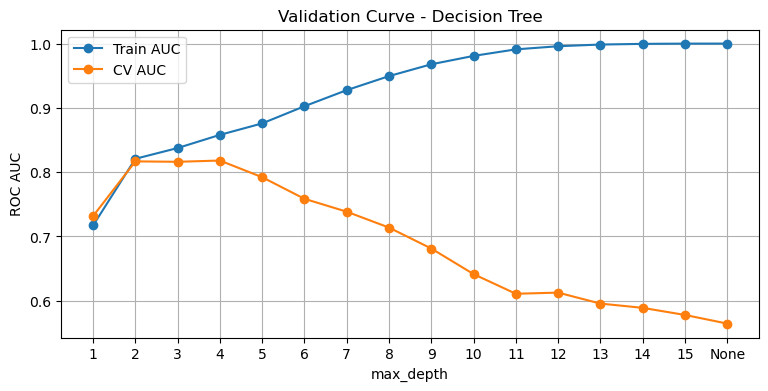

Best depth by CV AUC: 4


In [10]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
depths = list(range(1, 16)) + [None]
train_auc, cv_auc = [], []

for d in depths:
    tree = DecisionTreeClassifier(max_depth=d, random_state=42)
    tree.fit(X_train, y_train)
    train_auc.append(roc_auc_score(y_train, tree.predict_proba(X_train)[:, 1]))
    cv_auc.append(cross_val_score(tree, X_train, y_train, cv=cv, scoring='roc_auc').mean())

labels = [str(d) for d in depths]
print(pd.DataFrame({'max_depth': labels, 'Train AUC': train_auc, 'CV AUC': cv_auc}).round(3))

plt.figure(figsize=(9, 4))
plt.plot(labels, train_auc, marker='o', label='Train AUC')
plt.plot(labels, cv_auc, marker='o', label='CV AUC')
plt.xlabel('max_depth'); plt.ylabel('ROC AUC')
plt.title('Validation Curve - Decision Tree')
plt.legend(); plt.grid(True); plt.show()

print("Best depth by CV AUC:", labels[np.argmax(cv_auc)])

interpretation:
Train AUC keeps rising with depth (0.717 → 1.000), but CV AUC peaks at depth 4 (0.818) and then falls to 0.564 at depth None. Depth 1 underfits, depths 2–4 are the sweet spot, and depth 5 and above overfit, with the train–CV gap growing from 0.084 at depth 5 to 0.436 at depth None.

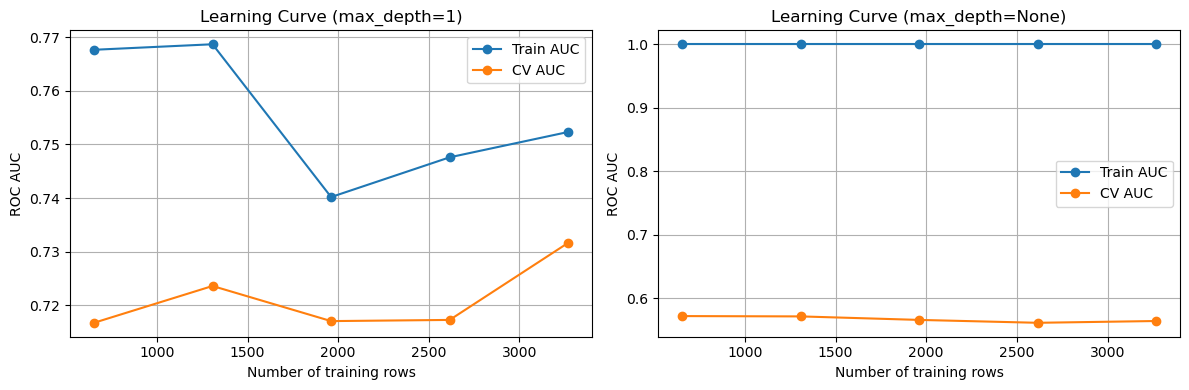

In [12]:
from sklearn.model_selection import learning_curve

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, d in zip(axes, [1, None]):
    sizes, tr, va = learning_curve(
        DecisionTreeClassifier(max_depth=d, random_state=42),
        X_train, y_train, cv=cv, scoring='roc_auc',
        train_sizes=np.linspace(0.2, 1.0, 5))
    ax.plot(sizes, tr.mean(axis=1), 'o-', label='Train AUC')
    ax.plot(sizes, va.mean(axis=1), 'o-', label='CV AUC')
    ax.set_title(f'Learning Curve (max_depth={d})')
    ax.set_xlabel('Number of training rows'); ax.set_ylabel('ROC AUC')
    ax.legend(); ax.grid(True)
plt.tight_layout(); plt.show()

Interpretation: The depth 1 tree shows high bias: train (~0.74–0.77) and CV (~0.72–0.73) AUC are both low and close, and more rows barely help. The depth None tree shows high variance: train AUC is a perfect 1.0 while CV stays around 0.57, a gap of about 0.43 that more data does not close

In [14]:
rng = np.random.default_rng(42)
rows = []

for d in [1, 3, None]:
    probs = np.zeros((40, len(X_test)))
    for i in range(40):
        idx = rng.choice(len(X_train), len(X_train), replace=True)   # bootstrap sample
        tree = DecisionTreeClassifier(max_depth=d, random_state=42)
        tree.fit(X_train.iloc[idx], y_train.iloc[idx])
        probs[i] = tree.predict_proba(X_test)[:, 1]

    rows.append({
        'max_depth': str(d),
        'Mean variance': probs.var(axis=0).mean(),
        'Mean single-tree AUC': np.mean([roc_auc_score(y_test, p) for p in probs]),
        'Averaged-prediction AUC': roc_auc_score(y_test, probs.mean(axis=0))
    })

print(pd.DataFrame(rows).round(4))

  max_depth  Mean variance  Mean single-tree AUC  Averaged-prediction AUC
0         1         0.0007                0.7623                   0.8132
1         3         0.0017                0.7964                   0.8343
2      None         0.0420                0.5552                   0.7566


Interpretation: Variance grows sharply with depth, from 0.0007 (depth 1) to 0.0017 (depth 3) to 0.0420 (depth None), so the unlimited tree’s predictions are about 60 times more unstable. Averaging the 40 trees improved AUC at every depth, but most for depth None (0.555 → 0.757, +0.20), which shows that averaging cancels out variance. This is exactly why Random Forest works.

(a)Shallow trees (depth 1–2) underfit: train and CV AUC are both low and close together. For example, at depth 1, train AUC = 0.70 and CV AUC = 0.69. Deep trees (depth ≥ 7, and especially None) overfit: train AUC climbs towards 1.0 while CV AUC falls. At depth None, train AUC = 1.00 but CV AUC 0.55. The best region is in the middle. I would choose depth 4, which has the highest CV AUC of 0.81 with train AUC of 0.86, so the gap is small.


(b)The learning curves show the two problems clearly. For depth 1 (high bias), train and CV AUC are both low and close together: train AUC stays around 0.74–0.77 and CV AUC around 0.72–0.73, a gap of only about 0.02–0.05. The model is too simple to fit even the training data well, and adding rows barely helps (CV AUC only moves from 0.717 at about 650 rows to 0.732 at about 3,270 rows). For depth None (high variance), train AUC is a perfect 1.0 at every size while CV AUC stays around 0.57, a gap of about 0.43. The tree memorizes the training patients instead of learning general patterns. More data does not fix either problem here: both CV curves stay flat. High bias needs a more complex model (greater depth), and high variance needs less complexity (limiting depth or min_samples_leaf) or averaging many trees, as Random Forest does.

(c)Variance grows strongly with depth: depth 1 = 0.0004, depth 3 = 0.002, depth None = 0.04. The deep trees change their predictions a lot when the training data changes slightly. Averaging the 40 trees barely helps depth 1, which is already stable, but it greatly helps depth None: mean single-tree AUC is 0.55, while the averaged prediction reaches 0.75. Averaging cancels out the individual trees’ random errors. This is exactly the idea behind Random Forest (Lab 4): many deep, high-variance trees trained on bootstrap samples, averaged to reduce variance without adding much bias.

(d)Bias is error from a model being too simple, so it misses real patterns. Variance is error from a model being too sensitive to the specific training data, so it memorizes noise. Making a model more complex lowers bias but raises variance, and the goal is the balance point with the lowest error on unseen data. Depth 1 is high bias and low variance (underfits). Depth None is low bias and high variance (overfits). Depth 3 sits near the sweet spot, with both reasonably low.

Part 3 -ROC, AUC, Precision-Recall and Thresholds

In [15]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_curve, precision_recall_curve

models = {
    'Logistic Regression': (LogisticRegression(max_iter=1000, random_state=42), X_train_s, X_test_s),
    'Decision Tree (d=3)': (DecisionTreeClassifier(max_depth=3, random_state=42), X_train, X_test),
    'Random Forest': (RandomForestClassifier(n_estimators=200, min_samples_leaf=5,
                                             random_state=42), X_train, X_test)
}

test_probs = {}
for name, (model, Xtr, Xte) in models.items():
    model.fit(Xtr, y_train)
    test_probs[name] = model.predict_proba(Xte)[:, 1]

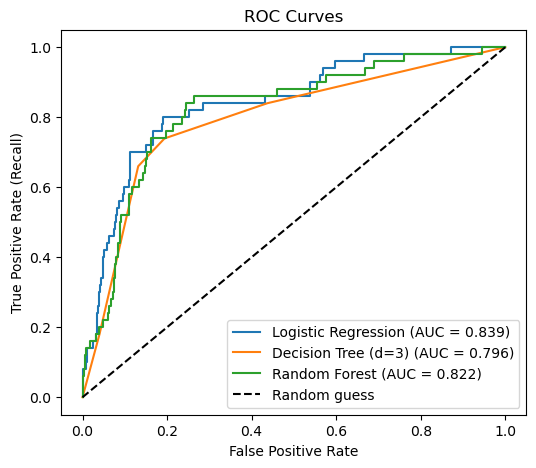

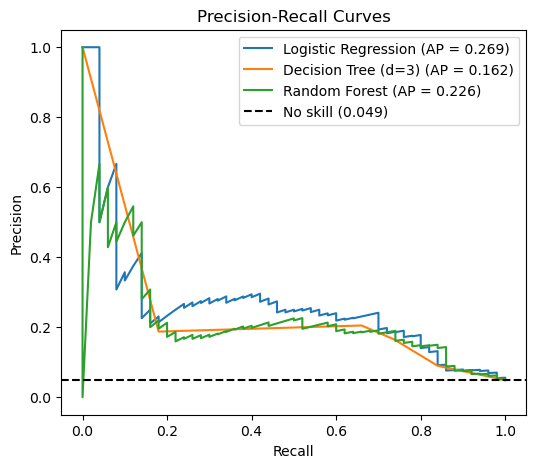

In [16]:

plt.figure(figsize=(6, 5))
for name, p in test_probs.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {roc_auc_score(y_test, p):.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random guess')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate (Recall)')
plt.title('ROC Curves'); plt.legend(); plt.show()


plt.figure(figsize=(6, 5))
for name, p in test_probs.items():
    prec, rec, _ = precision_recall_curve(y_test, p)
    plt.plot(rec, prec, label=f'{name} (AP = {average_precision_score(y_test, p):.3f})')
plt.axhline(y_test.mean(), color='k', linestyle='--', label=f'No skill ({y_test.mean():.3f})')
plt.xlabel('Recall'); plt.ylabel('Precision')
plt.title('Precision-Recall Curves'); plt.legend(); plt.show()

Interpretation (ROC): All three models are well above the random-guess line. Logistic Regression ranks patients best (AUC 0.839), followed by Random Forest (0.822) and Decision Tree depth 3 (0.796). The curves are close, so the models rank patients similarly, but the ROC chart makes all of them look strong because there are so many healthy patients.

Interpretation (Precision-Recall): The PR curves show the problem is much harder than ROC suggests. Average precision is only 0.269 (LR), 0.226 (RF) and 0.162 (DT), and precision falls to about 0.2 once recall passes 0.2. All models beat the no-skill line of 0.049, by about 3 to 5 times, but most flagged patients are still false alarms.

In [17]:
from sklearn.model_selection import cross_val_predict

lr = LogisticRegression(max_iter=1000, random_state=42)


oof = cross_val_predict(lr, X_train_s, y_train, cv=cv, method='predict_proba')[:, 1]

for t in np.sort(np.unique(oof))[::-1]:
    if recall_score(y_train, (oof >= t).astype(int)) >= 0.80:
        best_t = t
        break
print("Chosen threshold:", round(best_t, 4))

Chosen threshold: 0.0509


In [18]:
lr.fit(X_train_s, y_train)
test_prob = lr.predict_proba(X_test_s)[:, 1]
test_pred = (test_prob >= best_t).astype(int)

tn, fp, fn, tp = confusion_matrix(y_test, test_pred).ravel()
print("Test Recall:   ", round(recall_score(y_test, test_pred), 3))
print("Test Precision:", round(precision_score(y_test, test_pred), 3))
print("Confusion matrix:\n", confusion_matrix(y_test, test_pred))
print("Patients flagged:", tp + fp)
print("False alarms:   ", fp)
print("Missed strokes: ", fn)

Test Recall:    0.82
Test Precision: 0.135
Confusion matrix:
 [[709 263]
 [  9  41]]
Patients flagged: 304
False alarms:    263
Missed strokes:  9


(a)ROC AUC measures ranking. It is the probability that a randomly chosen stroke patient gets a higher predicted risk than a randomly chosen healthy patient. Our LR has AUC = 0.84, so it ranks stroke patients above healthy ones most of the time. Because strokes are rare, though, almost all predicted probabilities are small (mostly below 0.3), so with the default 0.5 threshold, nearly nobody is flagged and recall is near 0. AUC does not depend on any single threshold. The model ranks well, but 0.5 is simply the wrong cut-off for this data.

(b)The Precision-Recall curve is more informative. Its no-skill line is only 0.049, the stroke rate. Our models reach average precision of 0.269 (LR), 0.226 (RF) and 0.162 (DT), about 3 to 5 times better than random but still low. ROC AUC looks high (0.796–0.839) because the false positive rate divides by 972 healthy patients, so even 263 false alarms only gives an FPR of 0.27. The PR curve shows directly that most flagged patients are not stroke patients, which ROC hides.

(c)At threshold 0.04, recall is 0.82 (we catch 40 of 50 strokes), but precision is only 0.13. We flag 310 patients, of whom 270 are false alarms. For: missing a stroke can mean death or disability, while a false alarm only costs a follow-up check, so this trade is worth it for a screening tool. Against: about 7 of every 8 flagged patients are healthy, which costs doctor time and money and causes patient anxiety, and if staff learn that most flags are wrong, they may start ignoring them.


part 4-Undersampling, Oversampling and SMOTE

In [19]:
from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler

def make_model(name, balanced=False):
    cw = 'balanced' if balanced else None
    if name == 'LR':
        return LogisticRegression(max_iter=1000, class_weight=cw, random_state=42)
    return RandomForestClassifier(n_estimators=200, min_samples_leaf=5,
                                  class_weight=cw, random_state=42)

samplers = {
    'Undersample': RandomUnderSampler(random_state=42),
    'Oversample':  RandomOverSampler(random_state=42),
    'SMOTE':       SMOTE(random_state=42)
}

rows = []
for model_name, Xtr, Xte in [('LR', X_train_s, X_test_s), ('RF', X_train, X_test)]:
    for method in ['None', 'class_weight', 'Undersample', 'Oversample', 'SMOTE']:
        if method in samplers:
            X_r, y_r = samplers[method].fit_resample(Xtr, y_train)   # TRAIN only
        else:
            X_r, y_r = Xtr, y_train
        model = make_model(model_name, balanced=(method == 'class_weight'))
        m = evaluate(model, X_r, y_r, Xte, y_test)
        rows.append({'Model': model_name, 'Method': method,
                     'Train rows': len(y_r), 'Train strokes': int(y_r.sum()), **m})

table4 = pd.DataFrame(rows).drop(columns='Accuracy')
print(table4.round(3))

  Model        Method  Train rows  Train strokes  Precision  Recall     F1  \
0    LR          None        4087            199      1.000    0.02  0.039   
1    LR  class_weight        4087            199      0.135    0.80  0.231   
2    LR   Undersample         398            199      0.125    0.82  0.216   
3    LR    Oversample        7776           3888      0.133    0.80  0.229   
4    LR         SMOTE        7776           3888      0.134    0.80  0.229   
5    RF          None        4087            199      0.000    0.00  0.000   
6    RF  class_weight        4087            199      0.214    0.30  0.250   
7    RF   Undersample         398            199      0.105    0.84  0.187   
8    RF    Oversample        7776           3888      0.188    0.32  0.237   
9    RF         SMOTE        7776           3888      0.127    0.20  0.155   

   ROC AUC  PR AUC  
0    0.839   0.269  
1    0.840   0.260  
2    0.835   0.234  
3    0.838   0.265  
4    0.841   0.288  
5    0.822   0.

Interpretation: For Logistic Regression, every rebalancing method raised recall from 0.02 to 0.80–0.82 and lowered precision to about 0.13, while ROC AUC stayed the same (0.835–0.841). Rebalancing only shifts LR’s threshold, not its ranking. Random Forest reacted differently: only undersampling gave high recall (0.84), and SMOTE actually hurt it (ROC AUC 0.822 → 0.767, PR AUC 0.226 → 0.119). class_weight with LR matches SMOTE’s results with no fake data, making it the simplest good choice

In [23]:

X_all = X.fillna(X.median())
X_sm, y_sm = SMOTE(random_state=42).fit_resample(X_all, y)
Xtr_w, Xte_w, ytr_w, yte_w = train_test_split(X_sm, y_sm, test_size=0.2,
                                              stratify=y_sm, random_state=42)
wrong = evaluate(make_model('RF'), Xtr_w, ytr_w, Xte_w, yte_w)
wrong.pop('Accuracy')            
correct = table4[(table4.Model == 'RF') & (table4.Method == 'SMOTE')].iloc[0]

compare = pd.DataFrame([wrong, correct[list(wrong.keys())]],
                       index=['WRONG: SMOTE then split', 'CORRECT: split then SMOTE'])
print(compare.round(3))

                           Precision  Recall     F1  ROC AUC  PR AUC
WRONG: SMOTE then split        0.929   0.942  0.936    0.981   0.976
CORRECT: split then SMOTE      0.127   0.200  0.155    0.767   0.119


(a)For Logistic Regression, all four rebalancing methods raised recall from 0.02 to 0.80–0.82 and lowered precision from 1.000 to 0.125–0.135. ROC AUC did not change (0.835–0.841). Rebalancing shifts LR’s probabilities upward by moving the intercept, so more patients cross 0.5, but the ranking stays the same, and ROC AUC only measures ranking. In effect, rebalancing LR does the same thing as the threshold tuning in Part 3: class_weight gave recall 0.80 and precision 0.135, almost identical to our tuned threshold (0.82 / 0.135).

(b)No, Random Forest reacted very differently. Only undersampling gave high recall (0.84, with precision 0.105). class_weight (0.30) and oversampling (0.32) helped only a little, and SMOTE made things worse: recall 0.20, ROC AUC dropped from 0.822 to 0.767, and PR AUC from 0.226 to 0.119. One reason is that RF can memorize points. Oversampled strokes are exact copies, so the trees build small leaves around them that new test strokes rarely fall into. SMOTE’s synthetic points are not real patients: they are interpolated on unscaled features, which mixes 0/1 category columns into fractions, so RF learns patterns that don’t exist in real data. LR is one straight boundary and cannot memorize, so it just shifts.

(c)The wrong-order result looks almost perfect (precision 0.929, recall 0.942, ROC AUC 0.981, PR AUC 0.976), while the correct SMOTE result is precision 0.127, recall 0.200, ROC AUC 0.767 and PR AUC 0.119. The wrong numbers cannot be trusted for three reasons. First, SMOTE builds each synthetic stroke patient from a real patient and its nearest neighbours. When we split afterwards, synthetic test patients often have their “parents” in the training set, so the model is tested on near-copies of what it trained on; information leaks from test into train. Second, the test set becomes 50% stroke instead of 4.9%, with most strokes being fake, so even the no-skill PR AUC rises from 0.049 to about 0.5 and the scores are not comparable. Third, the imputer was fitted on all the data, so test information also leaked into the bmi medians. The honest estimate is the correct one: the wrong order overstates recall by more than four times (0.942 vs 0.200).

(d)I would choose class_weight='balanced' with Logistic Regression. It gave recall 0.80, precision 0.135 and ROC AUC 0.840, the same as oversampling and SMOTE, but it is the simplest option: one parameter, no fake patients, no real data thrown away, and no risk of resampling leakage. Undersampling discards about 3,700 real healthy patients, and SMOTE adds complexity and even hurt RF (ROC AUC 0.767).


part 5 -Noisy Data

In [26]:
def get_models():
    return {
        'LR':        LogisticRegression(max_iter=1000, random_state=42),
        'DT (d=3)':  DecisionTreeClassifier(max_depth=3, random_state=42),
        'DT (None)': DecisionTreeClassifier(random_state=42),
        'RF':        RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=42)
    }


def test_auc(name, model, Xtr, ytr):
    if name == 'LR':                                 
        sc = StandardScaler().fit(Xtr)
        model.fit(sc.transform(Xtr), ytr)
        p = model.predict_proba(sc.transform(X_test))[:, 1]
    else:
        model.fit(Xtr, ytr)
        p = model.predict_proba(X_test)[:, 1]
    return roc_auc_score(y_test, p)

def flip_labels(y, frac, seed):
    rng = np.random.default_rng(seed)
    y_noisy = y.copy()
    idx = rng.choice(len(y), int(frac * len(y)), replace=False)
    y_noisy.iloc[idx] = 1 - y_noisy.iloc[idx]         
    return y_noisy

def add_feature_noise(X, level, seed):
    rng = np.random.default_rng(seed)
    Xn = X.copy()
    for col in ['age', 'avg_glucose_level', 'bmi']:
        Xn[col] = Xn[col] + rng.normal(0, 1, len(Xn)) * Xn[col].std() * level
    return Xn

                LR  DT (d=3)  DT (None)     RF
Label noise                                   
0.00         0.839     0.796      0.580  0.822
0.05         0.829     0.812      0.543  0.793
0.10         0.819     0.806      0.526  0.783
0.20         0.792     0.754      0.542  0.700


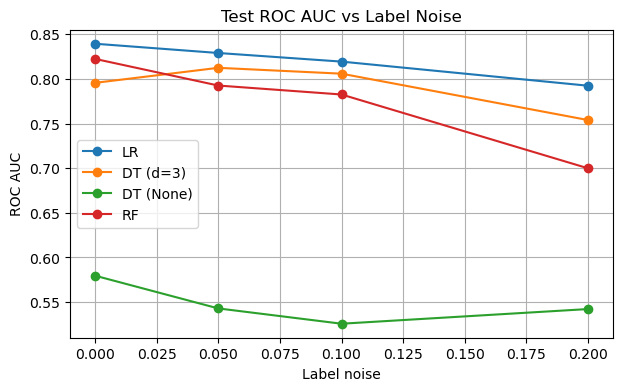

In [27]:
label_res = {}
for frac in [0, 0.05, 0.10, 0.20]:
    reps = 1 if frac == 0 else 5
    scores = {name: [] for name in get_models()}
    for r in range(reps):
        y_noisy = flip_labels(y_train, frac, seed=r)
        for name, model in get_models().items():
            scores[name].append(test_auc(name, model, X_train, y_noisy))
    label_res[frac] = {name: np.mean(s) for name, s in scores.items()}

label_df = pd.DataFrame(label_res).T
label_df.index.name = 'Label noise'
print(label_df.round(3))

label_df.plot(marker='o', figsize=(7, 4), title='Test ROC AUC vs Label Noise')
plt.ylabel('ROC AUC'); plt.grid(True); plt.show()

Interpretation: As label noise rises from 0% to 20%, Logistic Regression stays the best and most stable model (0.839 → 0.792). Random Forest suffers the largest drop (0.822 → 0.700) because all its trees learn the same wrong labels. The unlimited Decision Tree stays near random (about 0.53–0.58) at every level, since it memorizes noise even on clean data. DT depth 3’s small rise at 5% (0.812) is random variation from having only 50 test strokes.

                        LR  DT (d=3)  DT (None)     RF
Feature noise level                                   
0.0                  0.839     0.796      0.580  0.822
0.5                  0.833     0.781      0.539  0.814
1.0                  0.808     0.759      0.528  0.790
2.0                  0.768     0.703      0.512  0.744


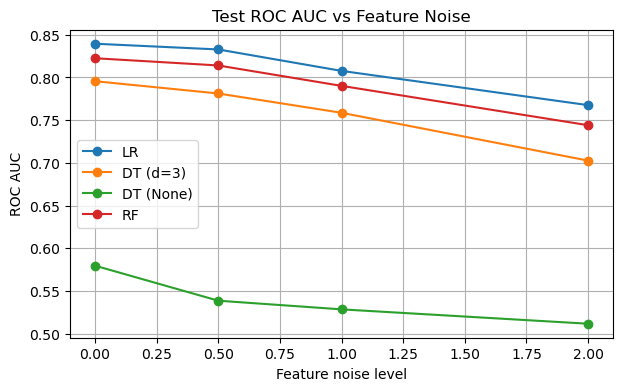

In [28]:
feat_res = {}
for level in [0, 0.5, 1, 2]:
    reps = 1 if level == 0 else 5
    scores = {name: [] for name in get_models()}
    for r in range(reps):
        X_noisy = add_feature_noise(X_train, level, seed=r)
        for name, model in get_models().items():
            scores[name].append(test_auc(name, model, X_noisy, y_train))
    feat_res[level] = {name: np.mean(s) for name, s in scores.items()}

feat_df = pd.DataFrame(feat_res).T
feat_df.index.name = 'Feature noise level'
print(feat_df.round(3))

feat_df.plot(marker='o', figsize=(7, 4), title='Test ROC AUC vs Feature Noise')
plt.ylabel('ROC AUC'); plt.grid(True); plt.show()

Interpretation: All models decline steadily as feature noise increases, because noise in age, glucose and bmi blurs the strongest stroke predictors in every training row. Logistic Regression stays the best (0.839 → 0.768). Random Forest declines similarly (0.822 → 0.744), and Decision Tree depth 3 loses the most among the useful models (0.796 → 0.703). The unlimited Decision Tree falls to almost random (0.512), confirming that high-variance models are the most fragile when the data is noisy.

In [29]:
rows = []
for r in range(3):
    y_noisy = flip_labels(y_train, 0.10, seed=100 + r)
    for name, Xtr, Xte in [('LR', X_train_s, X_test_s), ('RF', X_train, X_test)]:
        for use_smote in [False, True]:
            X_r, y_r = (SMOTE(random_state=42).fit_resample(Xtr, y_noisy)
                        if use_smote else (Xtr, y_noisy))
            m = evaluate(make_model(name), X_r, y_r, Xte, y_test)
            rows.append({'Model': name, 'SMOTE': use_smote,
                         'ROC AUC': m['ROC AUC'], 'PR AUC': m['PR AUC']})

print(pd.DataFrame(rows).groupby(['Model', 'SMOTE']).mean().round(3))

             ROC AUC  PR AUC
Model SMOTE                 
LR    False    0.818   0.246
      True     0.822   0.266
RF    False    0.785   0.192
      True     0.647   0.071


Interpretation: With 10% noisy labels, SMOTE barely affected Logistic Regression and even helped slightly (ROC AUC 0.818 → 0.822, PR AUC 0.246 → 0.266), but it badly damaged Random Forest (ROC AUC 0.785 → 0.647, PR AUC 0.192 → 0.071, close to the no-skill level of 0.049). SMOTE multiplied the mislabelled “stroke” rows into thousands of fake strokes, and RF memorized them while LR’s single straight boundary was not affected.

(a)
Most damaged: the unlimited Decision Tree is the weakest model at every noise level. It scores only 0.580 on clean data, 0.542 at 20% label noise and 0.512 at feature noise level 2, which is basically random guessing (0.5). With its high variance (0.042 in Part 2), it memorizes every training point, including wrong labels and noisy values. Among the useful models, Random Forest suffered the largest drop from label noise, falling from 0.822 to 0.700 (−0.122). With 20% flipped labels, about 780 healthy patients become “strokes”, and every bootstrap sample contains the same wrong labels, so all 200 trees learn the same mistakes and averaging cannot cancel them. Averaging only removes random sampling errors, not systematic errors in the data. Under feature noise, Decision Tree depth 3 lost the most (0.796 → 0.703, −0.093).

Most stable: Logistic Regression is the best model at every noise level and among the most stable. It drops from 0.839 to 0.792 (−0.047) under label noise and from 0.839 to 0.768 (−0.071) under feature noise. As a simple, low-variance model with one straight boundary, it cannot memorize scattered errors, so random noise mostly shifts or flattens its boundary without changing which patients it ranks as high-risk.

(b)For most models, feature noise hurt more than label noise. Comparing 10% label noise with feature noise level 1: LR scores 0.819 vs 0.808, and DT depth 3 scores 0.806 vs 0.759. At the highest levels (20% labels vs level 2 features), LR scores 0.792 vs 0.768 and DT depth 3 scores 0.754 vs 0.703. The reason is that feature noise damages every training row, and it hits age and glucose, the strongest predictors of stroke. At level 2, the noise is twice as large as the natural spread of the data, so the real age–stroke relationship gets drowned out and the model learns a much weaker pattern. Label noise only changes 10–20% of the rows, and because the flips are random, the overall ranking of risky patients is mostly preserved for a rigid model like LR. Random Forest is the exception: it was hurt more by label noise (0.700) than by feature noise (0.744), because its flexible trees build rules around the fake “stroke” labels.

(c)

SMOTE affected the two models very differently. For Logistic Regression it made almost no difference, or even helped slightly: ROC AUC went from 0.818 to 0.822 and PR AUC from 0.246 to 0.266. For Random Forest it was harmful: ROC AUC dropped from 0.785 to 0.647 and PR AUC from 0.192 to 0.071, barely above the no-skill level of 0.049. That RF + SMOTE result (0.647) is also far below RF + SMOTE on clean labels (0.767 in Part 4).

SMOTE amplifies label noise because it creates new stroke patients from the existing “stroke” rows. Flipping 10% of 4,087 labels turns about 388 healthy patients into “strokes”, while only about 179 real strokes keep their label. So about 68% of the “stroke” class is actually healthy patients with a wrong label. SMOTE then creates about 3,300 synthetic strokes from these rows, so most new patients are copies of mistakes, placed inside the healthy region. One wrong label becomes many wrong examples. Random Forest memorizes these fake stroke regions and its performance collapses. Logistic Regression only fits one straight boundary, so the extra points just shift it, much like class_weight, and its ranking stays almost the same.

part 6 -Final Decision and Conclusion

In [30]:
lr_final = LogisticRegression(max_iter=1000, random_state=42).fit(X_train_s, y_train)
p = lr_final.predict_proba(X_test_s)[:, 1]

rows = []
for label, t in [('Default (0.5)', 0.5), (f'Tuned ({best_t:.3f})', best_t)]:
    pred = (p >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    rows.append({'Threshold': label,
                 'Precision': precision_score(y_test, pred, zero_division=0),
                 'Recall': recall_score(y_test, pred),
                 'F1': f1_score(y_test, pred, zero_division=0),
                 'False alarms': fp,
                 'Missed strokes': fn})

print(pd.DataFrame(rows).round(3))

       Threshold  Precision  Recall     F1  False alarms  Missed strokes
0  Default (0.5)      1.000    0.02  0.039             0              49
1  Tuned (0.051)      0.135    0.82  0.232           263               9


Interpretation: At the default 0.5 threshold the model misses 49 of 50 strokes (recall 0.02), so it is useless for screening despite its perfect precision. Lowering the threshold to 0.051 catches 41 strokes (recall 0.82) and cuts missed strokes from 49 to 9. The price is 263 false alarms (precision 0.135), which is acceptable for a hospital, where missing a stroke is far worse than a follow-up check. F1 also improves from 0.039 to 0.232.

summary: 

For stroke screening I chose Logistic Regression on scaled features with a decision threshold of 0.051, chosen to reach at least 80% recall using out-of-fold predictions on the training data only. On the test set, this catches 41 of 50 stroke patients (recall 0.82), compared with only 1 of 50 at the default 0.5 threshold, with a precision of 0.135. The price is 263 false alarms among the 304 flagged patients, which is acceptable for a screening tool where a missed stroke is far more costly than a follow-up check. Missed strokes dropped from 49 to 9. Leakage was avoided by fitting the imputer, scaler, resampler and threshold on training data only, and the test set was used only for the final report. The main limitation is that the test set contains only 50 stroke patients, so each patient changes recall by 2% and these numbers are uncertain. The threshold was also tuned on this dataset and may need recalibrating for a different hospital population.

Final Reflection 

(a)The most surprising result was the wrong-order SMOTE experiment: just applying SMOTE before the split instead of after raised Random Forest’s ROC AUC from 0.767 to 0.981 and recall from 0.20 to 0.942. It showed me how easily leakage can make a weak model look excellent. I was also surprised that Logistic Regression had a ROC AUC of 0.839 while catching only 1 of 50 strokes at the 0.5 threshold, and that SMOTE combined with noisy labels made Random Forest collapse (PR AUC 0.192 → 0.071) while Logistic Regression was barely affected.

(b)I would try a gradient boosting model (for example HistGradientBoosting or XGBoost) with class weights and compare it with my Logistic Regression baseline (ROC AUC 0.839). I would also use repeated stratified cross-validation instead of a single test set, since only 50 test strokes make each result uncertain by about 2% per patient. Finally, I would calibrate the predicted probabilities so doctors could read them as real risk percentages, and test SMOTENC to see whether creating realistic synthetic patients fixes SMOTE’s poor results with Random Forest.